In [1]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path

import sys
import json
import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

In [2]:
PROJECT_DIR = Path(r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca")

DATASET_DIR = (
    PROJECT_DIR / "dataset" / "raw" / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"

REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR = PROJECT_DIR / "models"

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(PROJECT_DIR)
    )

In [3]:
from src.utils import (
    set_seed,
    get_device
)

from src.model_factory import (
    MODEL_REGISTRY,
    create_model,
    get_available_models,
    get_classifier,
    configure_trainable_layers,
    set_model_train_mode,
    count_parameters
)

from src.preprocessing import build_transforms

from src.data_generator import create_fold_loaders

In [4]:
def load_json(filepath):

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as f:

        return json.load(f)


dataset_config = load_json(
    CONFIGS_DIR / "dataset_config.json"
)

training_config = load_json(
    CONFIGS_DIR / "training_config.json"
)

preprocessing_config = load_json(
    CONFIGS_DIR / "preprocessing_config.json"
)

In [5]:
SEED = dataset_config["seed"]

NUM_CLASSES = dataset_config[
    "dataset_statistics"
]["num_classes"]

CLASS_MAPPING = dataset_config["class_mapping"]

IMAGE_SIZE = tuple(
    preprocessing_config["image_size"]
)

ARCHITECTURES = training_config["architectures"]

DROPOUT = training_config["training"]["dropout"]

NUM_WORKERS = training_config["training"]["num_workers"]

DEVICE = get_device()

set_seed(SEED)

print("Dispositivo:", DEVICE)
print("Número de clases:", NUM_CLASSES)
print("Tamaño de imagen:", IMAGE_SIZE)
print("Dropout:", DROPOUT)
print("Arquitecturas:", ARCHITECTURES)

display(CLASS_MAPPING)

Dispositivo: cuda
Número de clases: 5
Tamaño de imagen: (224, 224)
Dropout: 0.2
Arquitecturas: ['mobilenet_v3_large', 'efficientnet_b0', 'resnet50', 'vit_b_16', 'swin_t']


{'bacterial_blight': 0,
 'brown_streak_disease': 1,
 'green_mottle': 2,
 'healthy': 3,
 'mosaic_disease': 4}

In [6]:
print(
    "CuBLAS Workspace:",
    os.environ.get("CUBLAS_WORKSPACE_CONFIG")
)

print(
    "Algoritmos deterministas:",
    torch.are_deterministic_algorithms_enabled()
)

print(
    "CuDNN determinista:",
    torch.backends.cudnn.deterministic
)

print(
    "CuDNN benchmark:",
    torch.backends.cudnn.benchmark
)

print(
    "CUDA disponible:",
    torch.cuda.is_available()
)

CuBLAS Workspace: :4096:8
Algoritmos deterministas: True
CuDNN determinista: True
CuDNN benchmark: False
CUDA disponible: True


In [7]:
available_models = get_available_models()

assert set(ARCHITECTURES).issubset(
    available_models
)

assert NUM_CLASSES == len(CLASS_MAPPING)

assert IMAGE_SIZE == (224, 224)

assert sorted(CLASS_MAPPING.values()) == list(
    range(NUM_CLASSES)
)

for model_name in available_models:

    print(
        model_name,
        "|",
        MODEL_REGISTRY[model_name]["family"]
    )

mobilenet_v3_large | CNN
efficientnet_b0 | CNN
resnet50 | CNN
vit_b_16 | Transformer
swin_t | Transformer


In [8]:
MODEL_NAME = "mobilenet_v3_large"

model = create_model(
    model_name=MODEL_NAME,
    num_classes=NUM_CLASSES,
    pretrained=True,
    dropout=DROPOUT,
    mode="feature_extraction",
    device=DEVICE
)

print("Modelo creado correctamente.")

print(
    get_classifier(
        model,
        MODEL_NAME
    )
)

Modelo creado correctamente.
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=1280, out_features=5, bias=True)
)


In [9]:
print(torch.hub.get_dir())

C:\Users\Joseph (YO)/.cache\torch\hub


In [10]:
model_parameters = count_parameters(model)

for key, value in model_parameters.items():

    if isinstance(value, float):

        print(f"{key}: {value:.4f}")

    else:

        print(f"{key}: {value:,}")

total_parameters: 4,208,437
trainable_parameters: 1,236,485
frozen_parameters: 2,971,952
trainable_percentage: 29.3811


In [11]:
dummy_input = torch.randn(
    2,
    3,
    IMAGE_SIZE[0],
    IMAGE_SIZE[1],
    device=DEVICE
)

model.eval()

with torch.inference_mode():

    outputs = model(dummy_input)

print("Entrada:", dummy_input.shape)

print("Salida:", outputs.shape)

print("Dispositivo:", outputs.device)

assert outputs.shape == (
    2,
    NUM_CLASSES
)

assert torch.isfinite(outputs).all()

Entrada: torch.Size([2, 3, 224, 224])
Salida: torch.Size([2, 5])
Dispositivo: cuda:0


In [12]:
probabilities = torch.softmax(
    outputs,
    dim=1
)

predictions = probabilities.argmax(
    dim=1
)

print("Probabilidades:")

print(probabilities)

print("Suma por imagen:")

print(
    probabilities.sum(dim=1)
)

print("Predicciones:", predictions)

assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones(2, device=DEVICE),
    atol=1e-5
)

Probabilidades:
tensor([[0.1466, 0.2243, 0.2214, 0.2008, 0.2070],
        [0.1391, 0.2338, 0.2123, 0.2028, 0.2119]], device='cuda:0')
Suma por imagen:
tensor([1.0000, 1.0000], device='cuda:0')
Predicciones: tensor([1, 1], device='cuda:0')


In [13]:
training_modes = [
    "feature_extraction",
    "partial_finetuning",
    "full_finetuning"
]

mode_results = []

for mode in training_modes:

    configure_trainable_layers(
        model=model,
        model_name=MODEL_NAME,
        mode=mode
    )

    params = count_parameters(model)

    mode_results.append({
        "mode": mode,
        **params
    })

df_modes = pd.DataFrame(
    mode_results
)

display(df_modes)

,mode,total_parameters,trainable_parameters,frozen_parameters,trainable_percentage
0,feature_extraction,4208437,1236485,2971952,29.381098
1,partial_finetuning,4208437,2189365,2019072,52.023233
2,full_finetuning,4208437,4208437,0,100.000000


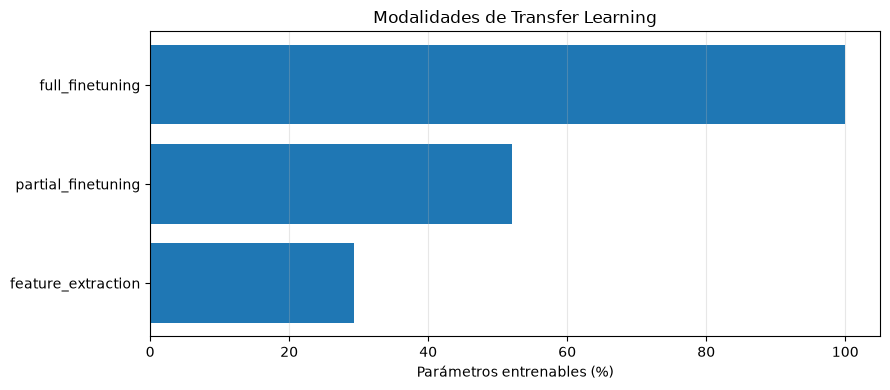

In [14]:
plt.figure(figsize=(9, 4))

plt.barh(
    df_modes["mode"],
    df_modes["trainable_percentage"]
)

plt.xlabel("Parámetros entrenables (%)")

plt.title(
    "Modalidades de Transfer Learning"
)

plt.xlim(0, 105)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [15]:
configure_trainable_layers(
    model=model,
    model_name=MODEL_NAME,
    mode="feature_extraction"
)

set_model_train_mode(
    model,
    MODEL_NAME
)

classifier = get_classifier(
    model,
    MODEL_NAME
)

assert classifier.training

assert all(
    p.requires_grad
    for p in classifier.parameters()
)

print("Clasificador en entrenamiento.")

print("Backbone congelado.")

Clasificador en entrenamiento.
Backbone congelado.


In [16]:
del model
del classifier
del dummy_input
del outputs
del probabilities
del predictions

gc.collect()

if DEVICE.type == "cuda":

    torch.cuda.empty_cache()

In [17]:
def inspect_model(model_name):

    model = None
    x = None
    outputs = None

    try:

        set_seed(SEED)

        model = create_model(
            model_name=model_name,
            num_classes=NUM_CLASSES,
            pretrained=True,
            dropout=DROPOUT,
            mode="feature_extraction",
            device=DEVICE
        )

        model.eval()

        x = torch.randn(
            2,
            3,
            *IMAGE_SIZE,
            device=DEVICE
        )

        with torch.inference_mode():

            outputs = model(x)

        assert outputs.shape == (
            2,
            NUM_CLASSES
        )

        assert torch.isfinite(outputs).all()

        params = count_parameters(model)

        result = {
            "architecture": model_name,
            "family": MODEL_REGISTRY[model_name]["family"],
            "pretrained_weights": str(
                MODEL_REGISTRY[model_name]["weights"]
            ),
            "num_classes": NUM_CLASSES,
            "input_shape": str(tuple(x.shape)),
            "output_shape": str(tuple(outputs.shape)),
            "status": "success",
            **params
        }

        return result

    finally:

        del model, x, outputs

        gc.collect()

        if DEVICE.type == "cuda":

            torch.cuda.empty_cache()

In [18]:
architecture_results = []

for model_name in ARCHITECTURES:

    print(f"\nVerificando: {model_name}")

    result = inspect_model(
        model_name
    )

    architecture_results.append(
        result
    )

    print("Estado:", result["status"])

    print(
        "Parámetros totales:",
        f'{result["total_parameters"]:,}'
    )

    print(
        "Parámetros entrenables:",
        f'{result["trainable_parameters"]:,}'
    )

df_architectures = pd.DataFrame(
    architecture_results
)

display(df_architectures)


Verificando: mobilenet_v3_large
Estado: success
Parámetros totales: 4,208,437
Parámetros entrenables: 1,236,485

Verificando: efficientnet_b0
Estado: success
Parámetros totales: 4,013,953
Parámetros entrenables: 6,405

Verificando: resnet50
Estado: success
Parámetros totales: 23,518,277
Parámetros entrenables: 10,245

Verificando: vit_b_16
Estado: success
Parámetros totales: 85,802,501
Parámetros entrenables: 3,845

Verificando: swin_t
Estado: success
Parámetros totales: 27,523,199
Parámetros entrenables: 3,845


,architecture,family,pretrained_weights,num_classes,input_shape,output_shape,status,total_parameters,trainable_parameters,frozen_parameters,trainable_percentage
0,mobilenet_v3_large,CNN,MobileNet_V3_Large_Weights.IMAGENET1K_V2,5,"(2, 3, 224, 224)","(2, 5)",success,4208437,1236485,2971952,29.381098
1,efficientnet_b0,CNN,EfficientNet_B0_Weights.IMAGENET1K_V1,5,"(2, 3, 224, 224)","(2, 5)",success,4013953,6405,4007548,0.159568
2,resnet50,CNN,ResNet50_Weights.IMAGENET1K_V2,5,"(2, 3, 224, 224)","(2, 5)",success,23518277,10245,23508032,0.043562
3,vit_b_16,Transformer,ViT_B_16_Weights.IMAGENET1K_V1,5,"(2, 3, 224, 224)","(2, 5)",success,85802501,3845,85798656,0.004481
4,swin_t,Transformer,Swin_T_Weights.IMAGENET1K_V1,5,"(2, 3, 224, 224)","(2, 5)",success,27523199,3845,27519354,0.013970


In [19]:
architecture_report_path = (
    REPORTS_DIR / "model_architectures.csv"
)

df_architectures.to_csv(
    architecture_report_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Reporte guardado:",
    architecture_report_path
)

Reporte guardado: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\reports\model_architectures.csv


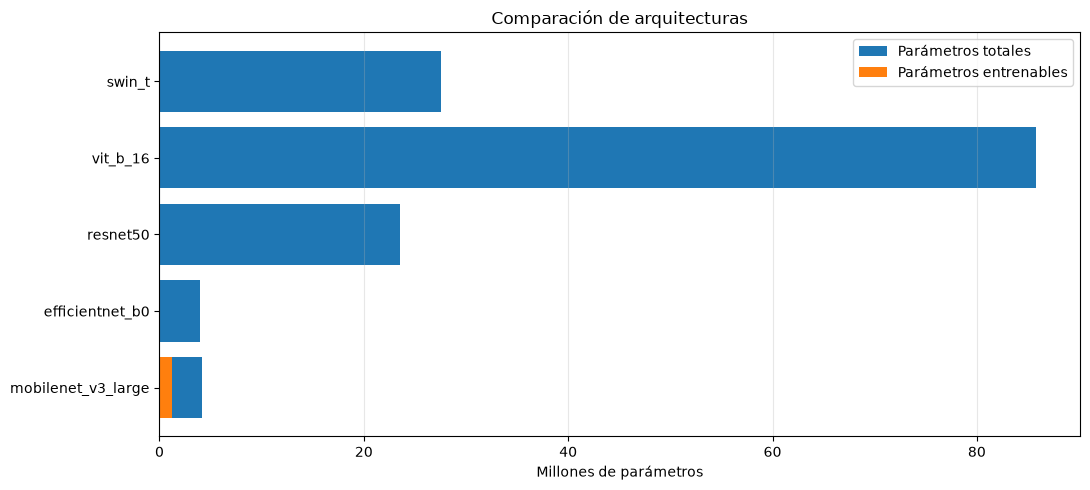

In [20]:
plt.figure(figsize=(11, 5))

plt.barh(
    df_architectures["architecture"],
    df_architectures["total_parameters"] / 1e6,
    label="Parámetros totales"
)

plt.barh(
    df_architectures["architecture"],
    df_architectures["trainable_parameters"] / 1e6,
    label="Parámetros entrenables"
)

plt.xlabel("Millones de parámetros")

plt.title(
    "Comparación de arquitecturas"
)

plt.legend()

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "model_parameters.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [21]:
df_splits = pd.read_csv(
    REPORTS_DIR / "dataset_splits.csv"
)

train_transform, eval_transform = build_transforms(
    CONFIGS_DIR / "preprocessing_config.json"
)

CURRENT_FOLD = 1

TEST_BATCH_SIZE = 4

In [22]:
train_loader, val_loader = create_fold_loaders(
    df_splits=df_splits,
    dataset_dir=DATASET_DIR,
    class_mapping=CLASS_MAPPING,
    train_transform=train_transform,
    eval_transform=eval_transform,
    fold=CURRENT_FOLD,
    batch_size=TEST_BATCH_SIZE,
    num_workers=NUM_WORKERS,
    seed=SEED
)

images, labels = next(
    iter(train_loader)
)

print("Imágenes:", images.shape)

print("Etiquetas:", labels.shape)

print("Tipo de imágenes:", images.dtype)

print("Tipo de etiquetas:", labels.dtype)

assert labels.dtype == torch.long

assert labels.min().item() >= 0

assert labels.max().item() < NUM_CLASSES

Imágenes: torch.Size([4, 3, 224, 224])
Etiquetas: torch.Size([4])
Tipo de imágenes: torch.float32
Tipo de etiquetas: torch.int64


In [23]:
def test_real_batch(
    model_name,
    images,
    labels
):

    model = None
    outputs = None
    loss = None
    x = None
    y = None

    try:

        model = create_model(
            model_name=model_name,
            num_classes=NUM_CLASSES,
            pretrained=True,
            dropout=DROPOUT,
            mode="feature_extraction",
            device=DEVICE
        )

        model.eval()

        x = images.to(DEVICE)

        y = labels.to(DEVICE)

        criterion = nn.CrossEntropyLoss()

        with torch.inference_mode():

            outputs = model(x)

            loss = criterion(
                outputs,
                y
            )

        assert outputs.shape == (
            len(images),
            NUM_CLASSES
        )

        assert torch.isfinite(loss)

        return {
            "architecture": model_name,
            "batch_size": len(images),
            "output_shape": str(tuple(outputs.shape)),
            "initial_loss": loss.item(),
            "status": "success"
        }

    finally:

        del model, outputs, loss, x, y

        gc.collect()

        if DEVICE.type == "cuda":

            torch.cuda.empty_cache()


real_batch_results = []

for model_name in ARCHITECTURES:

    print("Probando:", model_name)

    result = test_real_batch(
        model_name,
        images,
        labels
    )

    real_batch_results.append(result)

df_real_batch = pd.DataFrame(
    real_batch_results
)

display(df_real_batch)

Probando: mobilenet_v3_large
Probando: efficientnet_b0
Probando: resnet50
Probando: vit_b_16
Probando: swin_t


,architecture,batch_size,output_shape,initial_loss,status
0,mobilenet_v3_large,4,"(4, 5)",1.680245,success
1,efficientnet_b0,4,"(4, 5)",1.617255,success
2,resnet50,4,"(4, 5)",1.583424,success
3,vit_b_16,4,"(4, 5)",1.508769,success
4,swin_t,4,"(4, 5)",2.187871,success


In [24]:
def benchmark_model(
    model_name,
    batch_size,
    mode="feature_extraction",
    num_steps=3
):

    model = None
    optimizer = None
    scaler = None
    x = None
    y = None
    outputs = None
    loss = None

    use_amp = DEVICE.type == "cuda"

    try:

        set_seed(SEED)

        if use_amp:

            torch.cuda.empty_cache()

            torch.cuda.reset_peak_memory_stats()

        model = create_model(
            model_name=model_name,
            num_classes=NUM_CLASSES,
            pretrained=True,
            dropout=DROPOUT,
            mode=mode,
            device=DEVICE
        )

        set_model_train_mode(
            model,
            model_name
        )

        optimizer = torch.optim.AdamW(
            filter(
                lambda p: p.requires_grad,
                model.parameters()
            ),
            lr=0.001,
            weight_decay=0.0001
        )

        criterion = nn.CrossEntropyLoss()

        scaler = torch.amp.GradScaler(
            "cuda",
            enabled=use_amp
        )

        x = torch.randn(
            batch_size,
            3,
            *IMAGE_SIZE,
            device=DEVICE
        )

        y = torch.randint(
            0,
            NUM_CLASSES,
            (batch_size,),
            device=DEVICE
        )

        step_times = []

        for step in range(num_steps):

            if use_amp:

                torch.cuda.synchronize()

            start = time.perf_counter()

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=use_amp
            ):

                outputs = model(x)

                loss = criterion(
                    outputs,
                    y
                )

            if not torch.isfinite(loss):

                raise RuntimeError(
                    "La pérdida no es finita."
                )

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            if use_amp:

                torch.cuda.synchronize()

            elapsed = (
                time.perf_counter() - start
            )

            step_times.append(elapsed)

        # Excluir el primer paso de calentamiento
        measured_times = (
            step_times[1:]
            if len(step_times) > 1
            else step_times
        )

        avg_time = float(
            np.mean(measured_times)
        )

        peak_memory = (
            torch.cuda.max_memory_allocated()
            / 1024**2
            if use_amp
            else None
        )

        reserved_memory = (
            torch.cuda.max_memory_reserved()
            / 1024**2
            if use_amp
            else None
        )

        return {
            "architecture": model_name,
            "mode": mode,
            "batch_size": batch_size,
            "mixed_precision": use_amp,
            "seconds_per_batch": avg_time,
            "images_per_second": batch_size / avg_time,
            "peak_memory_mib": peak_memory,
            "reserved_memory_mib": reserved_memory,
            "status": "success"
        }

    except torch.cuda.OutOfMemoryError:

        return {
            "architecture": model_name,
            "mode": mode,
            "batch_size": batch_size,
            "status": "out_of_memory"
        }

    finally:

        del model, optimizer, scaler
        del x, y, outputs, loss

        gc.collect()

        if use_amp:

            torch.cuda.empty_cache()

In [25]:
benchmark_results = []

for model_name in ARCHITECTURES:

    batch_size = training_config[
        "model_settings"
    ][model_name]["batch_size"]

    print(
        f"\nModelo: {model_name}"
    )

    print(
        f"Batch size: {batch_size}"
    )

    result = benchmark_model(
        model_name=model_name,
        batch_size=batch_size,
        mode="feature_extraction",
        num_steps=3
    )

    benchmark_results.append(result)

    print(
        "Estado:",
        result["status"]
    )

df_benchmark = pd.DataFrame(
    benchmark_results
)

display(df_benchmark)


Modelo: mobilenet_v3_large
Batch size: 16
Estado: success

Modelo: efficientnet_b0
Batch size: 16
Estado: success

Modelo: resnet50
Batch size: 8
Estado: success

Modelo: vit_b_16
Batch size: 4
Estado: success

Modelo: swin_t
Batch size: 4
Estado: success


,architecture,mode,batch_size,mixed_precision,seconds_per_batch,images_per_second,peak_memory_mib,reserved_memory_mib,status
0,mobilenet_v3_large,feature_extraction,16,True,0.013493,1185.786862,153.974121,198.0,success
1,efficientnet_b0,feature_extraction,16,True,0.018914,845.938701,168.413574,218.0,success
2,resnet50,feature_extraction,8,True,0.020964,381.606564,201.672852,246.0,success
3,vit_b_16,feature_extraction,4,True,0.083011,48.186414,417.072266,468.0,success
4,swin_t,feature_extraction,4,True,0.018876,211.904251,215.919434,240.0,success


In [26]:
failed_models = df_benchmark[
    df_benchmark["status"] != "success"
]

if failed_models.empty:

    print(
        "Todas las arquitecturas superaron "
        "el benchmark inicial."
    )

else:

    print(
        "Arquitecturas que requieren ajustes:"
    )

    display(failed_models)

Todas las arquitecturas superaron el benchmark inicial.


In [27]:
df_benchmark.to_csv(
    REPORTS_DIR / "model_benchmark.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Benchmark guardado correctamente.")

Benchmark guardado correctamente.


In [28]:
num_train_images = len(
    train_loader.dataset
)

df_time_estimation = df_benchmark[
    df_benchmark["status"] == "success"
].copy()

df_time_estimation["train_images"] = (
    num_train_images
)

df_time_estimation["estimated_epoch_minutes"] = (
    df_time_estimation["train_images"]
    / df_time_estimation["images_per_second"]
    / 60
)

display(
    df_time_estimation[
        [
            "architecture",
            "batch_size",
            "images_per_second",
            "estimated_epoch_minutes"
        ]
    ]
)

,architecture,batch_size,images_per_second,estimated_epoch_minutes
0,mobilenet_v3_large,16,1185.786862,0.170407
1,efficientnet_b0,16,845.938701,0.238867
2,resnet50,8,381.606564,0.529516
3,vit_b_16,4,48.186414,4.193436
4,swin_t,4,211.904251,0.953575


In [29]:
model_config = {

    "framework": "PyTorch",

    "architecture_provider": "Torchvision",

    "num_classes": NUM_CLASSES,

    "class_mapping": CLASS_MAPPING,

    "image_size": list(IMAGE_SIZE),

    "pretrained": True,

    "default_dropout": DROPOUT,

    "default_training_mode": "feature_extraction",

    "available_training_modes": [
        "feature_extraction",
        "partial_finetuning",
        "full_finetuning"
    ],

    "output": {
        "type": "logits",
        "num_outputs": NUM_CLASSES,
        "softmax_in_model": False
    },

    "architectures": {}

}

for model_name in ARCHITECTURES:

    model_config["architectures"][model_name] = {

        "family": MODEL_REGISTRY[
            model_name
        ]["family"],

        "weights": str(
            MODEL_REGISTRY[model_name]["weights"]
        ),

        "batch_size": training_config[
            "model_settings"
        ][model_name]["batch_size"],

        "gradient_accumulation_steps": training_config[
            "model_settings"
        ][model_name]["gradient_accumulation_steps"]

    }

MODEL_CONFIG_PATH = (
    CONFIGS_DIR / "model_config.json"
)

with open(
    MODEL_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_config,
        f,
        indent=4
    )

print(
    "Configuración de modelos guardada."
)

Configuración de modelos guardada.


In [30]:
assert len(ARCHITECTURES) == 5

assert len(df_architectures) == 5

assert (
    df_architectures["family"] == "CNN"
).sum() == 3

assert (
    df_architectures["family"] == "Transformer"
).sum() == 2

assert (
    df_architectures["status"] == "success"
).all()

assert (
    df_real_batch["status"] == "success"
).all()

assert len(df_benchmark) == 5

assert (
    df_benchmark["status"] == "success"
).all(), "Hay modelos que requieren ajustes de memoria."

assert MODEL_CONFIG_PATH.exists()

print("=" * 50)

print("IMPLEMENTACIÓN DE ARQUITECTURAS COMPLETADA")

print("=" * 50)

print("CNN: 3")

print("Transformers: 2")

print("Clases:", NUM_CLASSES)

print("Transfer Learning: disponible")

print("Fine-Tuning: disponible")

print("Data Generator: compatible")

print("Benchmark: completado")

print("Dispositivo:", DEVICE)

IMPLEMENTACIÓN DE ARQUITECTURAS COMPLETADA
CNN: 3
Transformers: 2
Clases: 5
Transfer Learning: disponible
Fine-Tuning: disponible
Data Generator: compatible
Benchmark: completado
Dispositivo: cuda


In [31]:
partial_benchmark_results = []

for model_name in ARCHITECTURES:

    batch_size = training_config[
        "model_settings"
    ][model_name]["batch_size"]

    print(f"\nModelo: {model_name}")

    print("Modalidad: partial_finetuning")

    print("Batch size:", batch_size)

    result = benchmark_model(
        model_name=model_name,
        batch_size=batch_size,
        mode="partial_finetuning",
        num_steps=5
    )

    partial_benchmark_results.append(result)

    print("Estado:", result["status"])


df_partial_benchmark = pd.DataFrame(
    partial_benchmark_results
)

display(df_partial_benchmark)


Modelo: mobilenet_v3_large
Modalidad: partial_finetuning
Batch size: 16
Estado: success

Modelo: efficientnet_b0
Modalidad: partial_finetuning
Batch size: 16
Estado: success

Modelo: resnet50
Modalidad: partial_finetuning
Batch size: 8
Estado: success

Modelo: vit_b_16
Modalidad: partial_finetuning
Batch size: 4
Estado: success

Modelo: swin_t
Modalidad: partial_finetuning
Batch size: 4
Estado: success


,architecture,mode,batch_size,mixed_precision,seconds_per_batch,images_per_second,peak_memory_mib,reserved_memory_mib,status
0,mobilenet_v3_large,partial_finetuning,16,True,0.015982,1001.149758,161.249512,214.0,success
1,efficientnet_b0,partial_finetuning,16,True,0.021901,730.569422,177.664551,262.0,success
2,resnet50,partial_finetuning,8,True,0.036917,216.702186,392.081055,452.0,success
3,vit_b_16,partial_finetuning,4,True,0.092834,43.087894,610.614746,708.0,success
4,swin_t,partial_finetuning,4,True,0.033327,120.021634,389.223633,466.0,success


In [32]:
df_benchmark_comparison = pd.concat(
    [
        df_benchmark,
        df_partial_benchmark
    ],
    ignore_index=True
)

display(df_benchmark_comparison)

df_benchmark_comparison.to_csv(
    REPORTS_DIR / "model_benchmark_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

,architecture,mode,batch_size,mixed_precision,seconds_per_batch,images_per_second,peak_memory_mib,reserved_memory_mib,status
0,mobilenet_v3_large,feature_extraction,16,True,0.013493,1185.786862,153.974121,198.0,success
1,efficientnet_b0,feature_extraction,16,True,0.018914,845.938701,168.413574,218.0,success
2,resnet50,feature_extraction,8,True,0.020964,381.606564,201.672852,246.0,success
3,vit_b_16,feature_extraction,4,True,0.083011,48.186414,417.072266,468.0,success
4,swin_t,feature_extraction,4,True,0.018876,211.904251,215.919434,240.0,success
5,mobilenet_v3_large,partial_finetuning,16,True,0.015982,1001.149758,161.249512,214.0,success
6,efficientnet_b0,partial_finetuning,16,True,0.021901,730.569422,177.664551,262.0,success
7,resnet50,partial_finetuning,8,True,0.036917,216.702186,392.081055,452.0,success
8,vit_b_16,partial_finetuning,4,True,0.092834,43.087894,610.614746,708.0,success
9,swin_t,partial_finetuning,4,True,0.033327,120.021634,389.223633,466.0,success


In [33]:
df_comparison = df_benchmark.merge(
    df_partial_benchmark,
    on="architecture",
    suffixes=("_fe", "_ft"),
    validate="one_to_one"
)

df_comparison["speed_reduction_pct"] = (
    1 - (
        df_comparison["images_per_second_ft"]
        / df_comparison["images_per_second_fe"]
    )
) * 100

df_comparison["memory_increase_pct"] = (
    (
        df_comparison["peak_memory_mib_ft"]
        / df_comparison["peak_memory_mib_fe"]
    ) - 1
) * 100

df_comparison["estimated_epoch_fe_minutes"] = (
    len(train_loader.dataset)
    / df_comparison["images_per_second_fe"]
    / 60
)

df_comparison["estimated_epoch_ft_minutes"] = (
    len(train_loader.dataset)
    / df_comparison["images_per_second_ft"]
    / 60
)

comparison_columns = [
    "architecture",
    "batch_size_fe",
    "batch_size_ft",
    "images_per_second_fe",
    "images_per_second_ft",
    "speed_reduction_pct",
    "peak_memory_mib_fe",
    "peak_memory_mib_ft",
    "memory_increase_pct",
    "estimated_epoch_fe_minutes",
    "estimated_epoch_ft_minutes"
]

display(
    df_comparison[comparison_columns].round(4)
)

df_comparison[comparison_columns].to_csv(
    REPORTS_DIR / "model_performance_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

,architecture,batch_size_fe,batch_size_ft,images_per_second_fe,images_per_second_ft,speed_reduction_pct,peak_memory_mib_fe,peak_memory_mib_ft,memory_increase_pct,estimated_epoch_fe_minutes,estimated_epoch_ft_minutes
0,mobilenet_v3_large,16,16,1185.7869,1001.1498,15.5709,153.9741,161.2495,4.7251,0.1704,0.2018
1,efficientnet_b0,16,16,845.9387,730.5694,13.6380,168.4136,177.6646,5.4930,0.2389,0.2766
2,resnet50,8,8,381.6066,216.7022,43.2132,201.6729,392.0811,94.4144,0.5295,0.9325
3,vit_b_16,4,4,48.1864,43.0879,10.5808,417.0723,610.6147,46.4050,4.1934,4.6896
4,swin_t,4,4,211.9043,120.0216,43.3604,215.9194,389.2236,80.2634,0.9536,1.6836


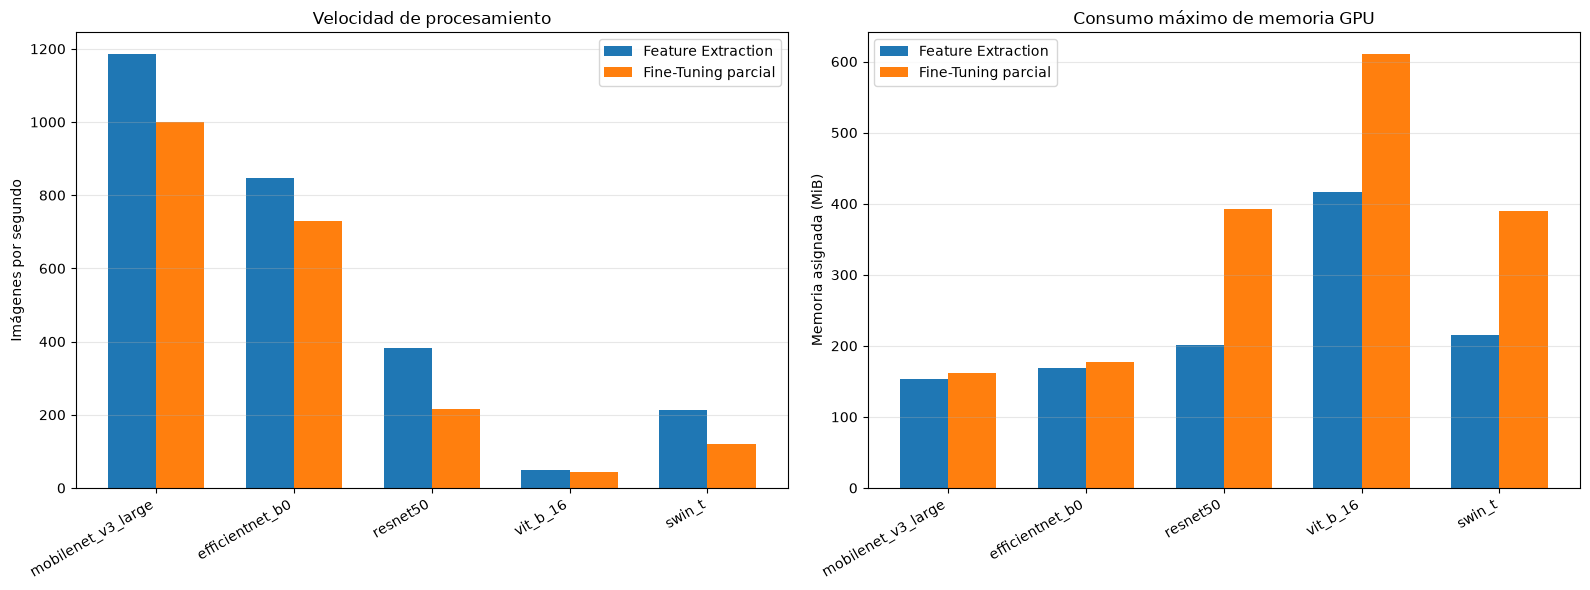

In [34]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

x = np.arange(len(df_comparison))

width = 0.35

# Velocidad de procesamiento
axes[0].bar(
    x - width / 2,
    df_comparison["images_per_second_fe"],
    width,
    label="Feature Extraction"
)

axes[0].bar(
    x + width / 2,
    df_comparison["images_per_second_ft"],
    width,
    label="Fine-Tuning parcial"
)

axes[0].set_title("Velocidad de procesamiento")
axes[0].set_ylabel("Imágenes por segundo")
axes[0].set_xticks(x)

axes[0].set_xticklabels(
    df_comparison["architecture"],
    rotation=30,
    ha="right"
)

axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Consumo de memoria
axes[1].bar(
    x - width / 2,
    df_comparison["peak_memory_mib_fe"],
    width,
    label="Feature Extraction"
)

axes[1].bar(
    x + width / 2,
    df_comparison["peak_memory_mib_ft"],
    width,
    label="Fine-Tuning parcial"
)

axes[1].set_title("Consumo máximo de memoria GPU")
axes[1].set_ylabel("Memoria asignada (MiB)")
axes[1].set_xticks(x)

axes[1].set_xticklabels(
    df_comparison["architecture"],
    rotation=30,
    ha="right"
)

axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "model_performance_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [35]:
assert len(df_benchmark) == 5

assert len(df_partial_benchmark) == 5

assert set(df_benchmark["architecture"]) == set(
    ARCHITECTURES
)

assert set(df_partial_benchmark["architecture"]) == set(
    ARCHITECTURES
)

assert (
    df_benchmark["status"] == "success"
).all()

assert (
    df_partial_benchmark["status"] == "success"
).all()

assert (
    df_benchmark["mixed_precision"]
).all()

assert (
    df_partial_benchmark["mixed_precision"]
).all()

assert torch.cuda.is_available()

assert torch.are_deterministic_algorithms_enabled()

assert not (
    torch.is_deterministic_algorithms_warn_only_enabled()
)

assert os.environ.get(
    "CUBLAS_WORKSPACE_CONFIG"
) in [":4096:8", ":16:8"]

assert len(df_benchmark_comparison) == 10

print("=" * 60)

print("FASE 2 - PARTE 2 COMPLETADA")

print("=" * 60)

print("Arquitecturas CNN: 3")
print("Arquitecturas Transformers: 2")
print("Feature Extraction: 5/5")
print("Fine-Tuning parcial: 5/5")
print("CUDA: disponible")
print("Mixed Precision: disponible")
print("Configuración determinista: activada")
print("Errores de memoria durante las pruebas: 0")
print("Modelos preparados para el pipeline de entrenamiento")

FASE 2 - PARTE 2 COMPLETADA
Arquitecturas CNN: 3
Arquitecturas Transformers: 2
Feature Extraction: 5/5
Fine-Tuning parcial: 5/5
CUDA: disponible
Mixed Precision: disponible
Configuración determinista: activada
Errores de memoria durante las pruebas: 0
Modelos preparados para el pipeline de entrenamiento
